# Risk Factors for Hypertension among US Adults: NHANES 2017-2018
**Biostatistics mini project, MSc Data Science**

How to use this notebook: run the cells from top to bottom (Runtime > Run all works too). Every section matches a unit of your syllabus. All tables and figures are saved in a folder called `results`, and the last cell downloads them as one zip file.

After each output cell, write 2 or 3 lines in your own words about what the result means. That is what your guide will ask about in the presentation.

In [1]:
%pip install -q pingouin

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [2]:
import os, re, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.proportion import proportion_confint
from scipy import stats
from sklearn.metrics import roc_curve, roc_auc_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
os.makedirs("results", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"results/{name}.png", dpi=150)
    plt.show()

def pfmt(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

def nice(name):
    """Turn a patsy term like C(sex, Treatment("Female"))[T.Male] into 'sex: Male (vs Female)'."""
    m = re.match(r'C\((\w+), Treatment\("(.+?)"\)\)\[T\.(.+)\]', name)
    if m:
        return f"{m.group(1)}: {m.group(3)} (vs {m.group(2)})"
    return {"age10": "age (per 10 years)", "bmi5": "BMI (per 5 units)"}.get(name, name)

def coef_table(model, expo=False):
    ci = model.conf_int()
    out = pd.DataFrame({"est": model.params, "low": ci[0], "high": ci[1], "p": model.pvalues})
    if expo:
        out[["est", "low", "high"]] = np.exp(out[["est", "low", "high"]])
    out = out.drop(index="Intercept")
    out.index = [nice(i) for i in out.index]
    out[["est", "low", "high"]] = out[["est", "low", "high"]].round(3)
    out["p"] = out["p"].map(pfmt)
    return out

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1. Load and merge the data
Six NHANES 2017-2018 files are joined on the respondent ID (`SEQN`). Only adults (18 and above) are kept.

In [3]:
base = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/"
files = ["DEMO_J", "BPX_J", "BMX_J", "SMQ_J", "DIQ_J", "BPQ_J"]

data = {f: pd.read_sas(base + f + ".xpt") for f in files}

raw = data["DEMO_J"]
for f in files[1:]:
    raw = raw.merge(data[f], on="SEQN", how="left")

raw = raw[raw["RIDAGEYR"] >= 18].copy()
print("Adults aged 18+:", raw.shape[0])

Adults aged 18+: 5856


## 2. Cleaning and new variables
Decisions made here (write these in your methods section):
- Diastolic readings below 20 mm Hg are not possible in a living adult, so they are set to missing.
- Diabetes: "Yes" and "No" are kept. "Borderline" and "Don't know" are set to missing.
- Smoking is built from two questions: never smoked 100 cigarettes = Never; smoked and now not at all = Former; smoked and now smoking (every day or some days) = Current.
- Systolic and diastolic BP are the mean of the readings available for each person.
- **Hypertension** = mean systolic 130 or above, or mean diastolic 80 or above, or taking BP medicine. The 140/90 version is kept for the sensitivity check.
- People with no BP reading at all have no hypertension status, so they are left out of the hypertension analyses.
- BMI groups: Normal (under 25, this includes the few underweight people), Overweight (25 to 29.9), Obese (30 and above).

In [4]:
keep = ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH3",
        "BPXSY1", "BPXSY2", "BPXSY3", "BPXDI1", "BPXDI2", "BPXDI3",
        "BMXBMI", "BMXWAIST", "SMQ020", "SMQ040", "DIQ010", "BPQ020", "BPQ050A"]
df = raw[keep].copy()
df["SEQN"] = df["SEQN"].astype(int)

# impossible diastolic values
for c in ["BPXDI1", "BPXDI2", "BPXDI3"]:
    df.loc[df[c] < 20, c] = np.nan

df["age"] = df["RIDAGEYR"]
df["bmi"] = df["BMXBMI"]
df["waist"] = df["BMXWAIST"]
df["sex"] = df["RIAGENDR"].map({1: "Male", 2: "Female"})
df["race"] = df["RIDRETH3"].map({1: "Mexican American", 2: "Other Hispanic", 3: "NH White",
                                 4: "NH Black", 6: "NH Asian", 7: "Other/Multiracial"})
df["diabetes"] = df["DIQ010"].map({1: "Yes", 2: "No"})

smoke = pd.Series(np.nan, index=df.index, dtype="object")
smoke[df["SMQ020"] == 2] = "Never"
smoke[df["SMQ040"] == 3] = "Former"
smoke[df["SMQ040"].isin([1, 2])] = "Current"
df["smoke"] = smoke

df["sbp"] = df[["BPXSY1", "BPXSY2", "BPXSY3"]].mean(axis=1)
df["dbp"] = df[["BPXDI1", "BPXDI2", "BPXDI3"]].mean(axis=1)
on_med = df["BPQ050A"] == 1

def make_htn(sys_cut, dia_cut):
    flag = ((df["sbp"] >= sys_cut) | (df["dbp"] >= dia_cut) | on_med).astype(float)
    return flag.where(df["sbp"].notna())      # no BP reading = unknown

df["htn"] = make_htn(130, 80)
df["htn140"] = make_htn(140, 90)

BMI_ORDER = ["Normal (<25)", "Overweight (25-29.9)", "Obese (30+)"]
df["bmi_cat"] = pd.cut(df["bmi"], [0, 25, 30, 500], right=False, labels=BMI_ORDER).astype(object)
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60-69", "70-80"]
df["age_grp"] = pd.cut(df["age"], [18, 30, 40, 50, 60, 70, 81], right=False, labels=AGE_ORDER).astype(object)

# scaled versions so odds ratios are per 10 years of age and per 5 BMI units
df["age10"] = df["age"] / 10
df["bmi5"] = df["bmi"] / 5

# analysis sample for the models: everyone with all variables present
model_vars = ["sbp", "age", "sex", "race", "bmi", "smoke", "diabetes"]
cc = df.dropna(subset=model_vars).copy()
cc["htn"] = cc["htn"].astype(int)

print("Adults:", len(df))
print("With a systolic reading (hypertension analyses):", df["sbp"].notna().sum())
print("With all 3 systolic readings (repeated measures):", df[["BPXSY1", "BPXSY2", "BPXSY3"]].notna().all(axis=1).sum())
print("Complete cases for the models:", len(cc))
print()
print("Smoking:", df["smoke"].value_counts().to_dict())
print("Diabetes:", df["diabetes"].value_counts().to_dict())
print("Hypertension prevalence (130/80 or medicine): %.1f%%" % (df["htn"].mean() * 100))
print("Hypertension prevalence (140/90 or medicine): %.1f%%" % (df["htn140"].mean() * 100))

Adults: 5856
With a systolic reading (hypertension analyses): 5247
With all 3 systolic readings (repeated measures): 4730
Complete cases for the models: 5017

Smoking: {'Never': 3497, 'Former': 1338, 'Current': 1021}
Diabetes: {'No': 4800, 'Yes': 878}
Hypertension prevalence (130/80 or medicine): 54.3%
Hypertension prevalence (140/90 or medicine): 40.3%


## 3. Missing data
Report this table in the methods. About one in five adults have at least one BP reading missing, so say that these people may differ from the ones with full readings.

In [5]:
check = ["age", "sex", "race", "bmi", "waist", "smoke", "diabetes", "sbp", "dbp", "htn"]
miss = pd.DataFrame({"missing_n": df[check].isna().sum(),
                     "missing_%": (df[check].isna().mean() * 100).round(1)})
print(miss)
miss.to_csv("results/missing_data.csv")

# are the people without BP readings different?
nobp = df[df["sbp"].isna()]
withbp = df[df["sbp"].notna()]
print("\nMean age, with BP reading: %.1f | without BP reading: %.1f" % (withbp["age"].mean(), nobp["age"].mean()))
print("Mean BMI, with BP reading: %.1f | without BP reading: %.1f" % (withbp["bmi"].mean(), nobp["bmi"].mean()))

          missing_n  missing_%
age               0        0.0
sex               0        0.0
race              0        0.0
bmi             422        7.2
waist           672       11.5
smoke             0        0.0
diabetes        178        3.0
sbp             609       10.4
dbp             626       10.7
htn             609       10.4

Mean age, with BP reading: 49.9 | without BP reading: 50.0
Mean BMI, with BP reading: 29.7 | without BP reading: 30.1


## 4. Descriptive analysis and Table 1 (Unit 1)

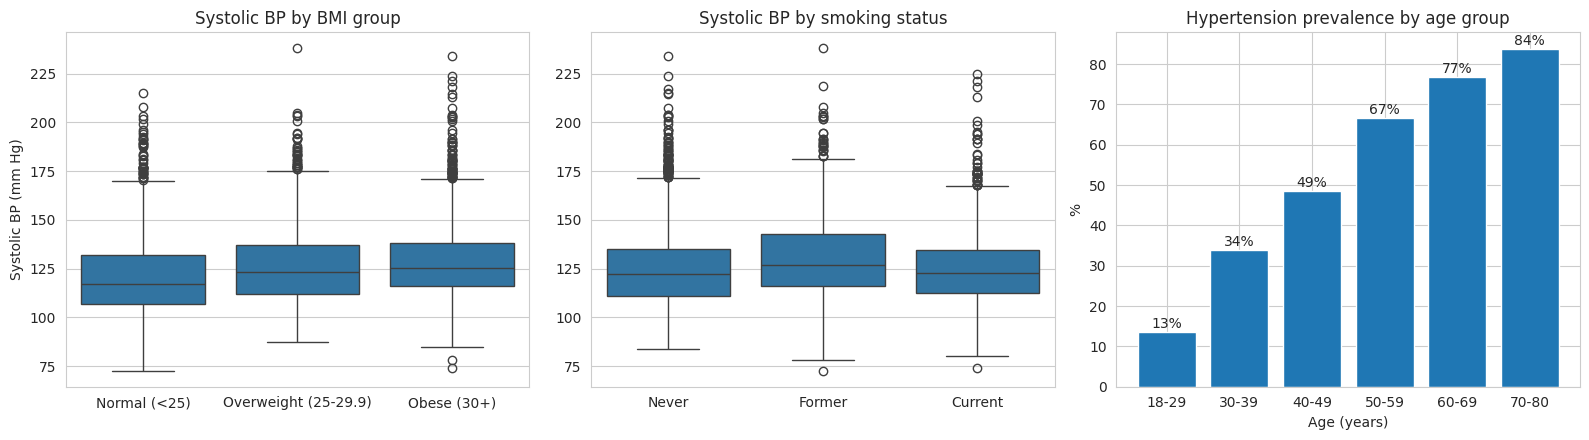

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

sns.boxplot(data=df.dropna(subset=["bmi_cat", "sbp"]), x="bmi_cat", y="sbp", order=BMI_ORDER, ax=ax[0])
ax[0].set_title("Systolic BP by BMI group"); ax[0].set_xlabel(""); ax[0].set_ylabel("Systolic BP (mm Hg)")

sns.boxplot(data=df.dropna(subset=["smoke", "sbp"]), x="smoke", y="sbp", order=["Never", "Former", "Current"], ax=ax[1])
ax[1].set_title("Systolic BP by smoking status"); ax[1].set_xlabel(""); ax[1].set_ylabel("")

prev_age = df.dropna(subset=["htn", "age_grp"]).groupby("age_grp")["htn"].mean().reindex(AGE_ORDER) * 100
ax[2].bar(prev_age.index, prev_age.values)
ax[2].set_title("Hypertension prevalence by age group"); ax[2].set_ylabel("%"); ax[2].set_xlabel("Age (years)")
for i, v in enumerate(prev_age.values):
    ax[2].text(i, v + 1, f"{v:.0f}%", ha="center")
save("fig1_descriptive")

In [7]:
t1 = df.dropna(subset=["htn"]).copy()
t1["htn"] = t1["htn"].astype(int)
no, yes = t1[t1["htn"] == 0], t1[t1["htn"] == 1]
rows = []

def add_num(var, label):
    a, b, allv = no[var].dropna(), yes[var].dropna(), t1[var].dropna()
    p_t = stats.ttest_ind(a, b, equal_var=False).pvalue
    p_u = stats.mannwhitneyu(a, b).pvalue
    rows.append([label, f"{allv.mean():.1f} ({allv.std():.1f})", f"{a.mean():.1f} ({a.std():.1f})",
                 f"{b.mean():.1f} ({b.std():.1f})", pfmt(p_t), pfmt(p_u)])

def add_cat(var, label, order):
    sub = t1.dropna(subset=[var])
    ct = pd.crosstab(sub[var], sub["htn"]).reindex(order)
    p = stats.chi2_contingency(ct)[1]
    rows.append([label + ", n (%)", "", "", "", pfmt(p), ""])
    tot = ct.values.sum()
    for lvl in order:
        n0, n1 = int(ct.loc[lvl, 0]), int(ct.loc[lvl, 1])
        rows.append(["    " + lvl, f"{n0+n1} ({(n0+n1)/tot*100:.1f}%)",
                     f"{n0} ({n0/ct[0].sum()*100:.1f}%)", f"{n1} ({n1/ct[1].sum()*100:.1f}%)", "", ""])

add_num("age", "Age, years: mean (SD)")
add_cat("sex", "Sex", ["Female", "Male"])
add_cat("race", "Race/ethnicity", ["NH White", "NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multiracial"])
add_num("bmi", "BMI, kg/m2: mean (SD)")
add_cat("bmi_cat", "BMI group", BMI_ORDER)
add_num("waist", "Waist, cm: mean (SD)")
add_cat("smoke", "Smoking", ["Never", "Former", "Current"])
add_cat("diabetes", "Diabetes", ["No", "Yes"])
add_num("sbp", "Systolic BP, mm Hg: mean (SD)")
add_num("dbp", "Diastolic BP, mm Hg: mean (SD)")

table1 = pd.DataFrame(rows, columns=["Variable", f"All (n={len(t1)})", f"No hypertension (n={len(no)})",
                                     f"Hypertension (n={len(yes)})", "p (t-test / chi-square)", "p (Mann-Whitney)"])
print(table1.to_string(index=False))
table1.to_csv("results/table1.csv", index=False)

                      Variable All (n=5247) No hypertension (n=2396) Hypertension (n=2851) p (t-test / chi-square) p (Mann-Whitney)
         Age, years: mean (SD)  49.9 (18.6)              39.6 (16.8)           58.5 (15.4)                  <0.001           <0.001
                    Sex, n (%)                                                                              <0.001                 
                        Female 2700 (51.5%)             1341 (56.0%)          1359 (47.7%)                                         
                          Male 2547 (48.5%)             1055 (44.0%)          1492 (52.3%)                                         
         Race/ethnicity, n (%)                                                                              <0.001                 
                      NH White 1819 (34.7%)              830 (34.6%)           989 (34.7%)                                         
                      NH Black 1220 (23.3%)              431 (18.0%)        

Note for the report: BP itself is in Table 1 only to describe the two groups. It is part of the definition of hypertension, so its p-value is not a finding.

## 5. Checking the distributions
With about 5,000 people, a normality test will reject for tiny departures, so the plots and the skewness matter more than the p-value. Shapiro-Wilk is run on a random subsample of 1,000 for that reason.

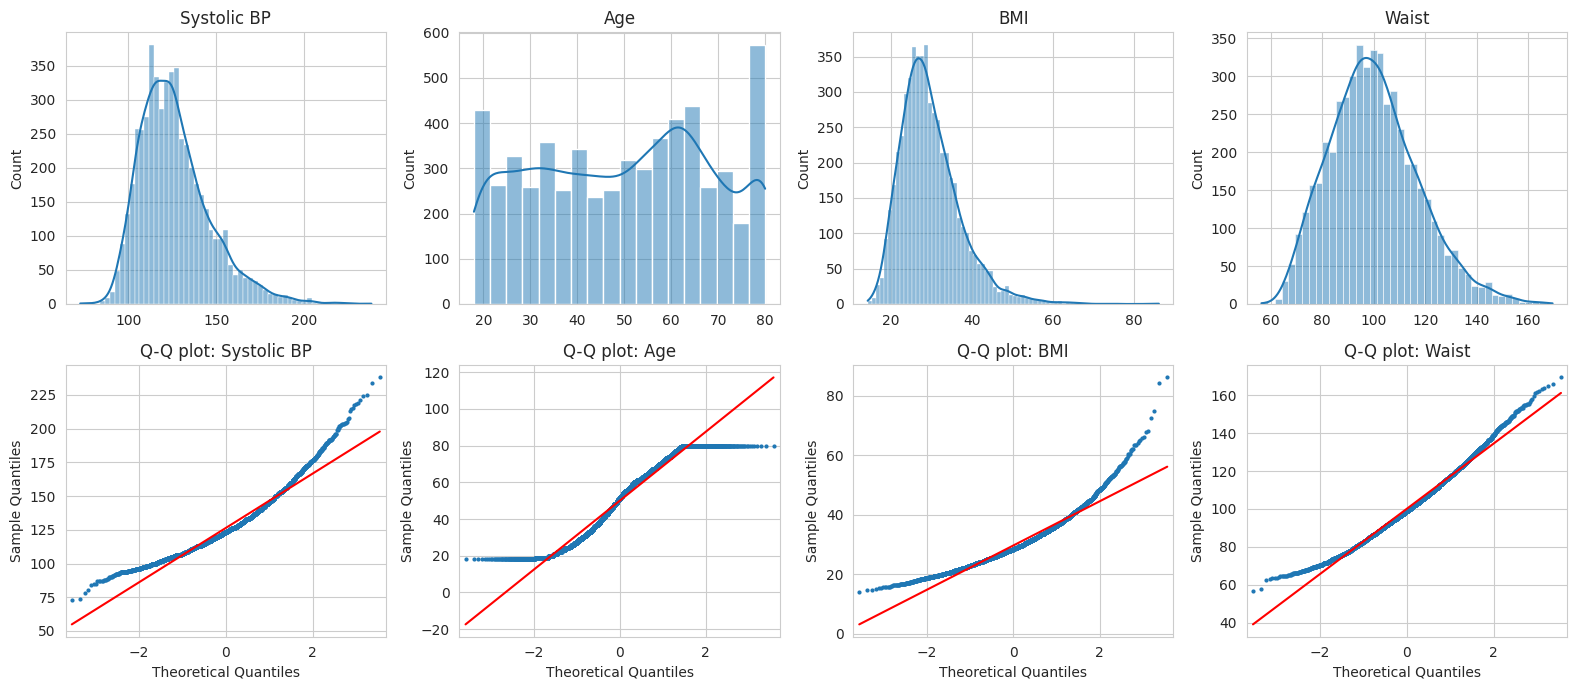

   Variable    n   Mean    SD  Skewness  Excess kurtosis  Shapiro W (n=1000) Shapiro p
Systolic BP 5247 126.36 20.13      1.04             1.68                0.93    <0.001
        Age 5856  49.89 18.78     -0.06            -1.17                0.96    <0.001
        BMI 5434  29.69  7.44      1.27             3.29                0.93    <0.001
      Waist 5184 100.16 17.22      0.48             0.18                0.98    <0.001


In [8]:
vars_ = [("sbp", "Systolic BP"), ("age", "Age"), ("bmi", "BMI"), ("waist", "Waist")]
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
rows = []
for i, (v, lab) in enumerate(vars_):
    x = df[v].dropna()
    sns.histplot(x, kde=True, ax=ax[0, i]); ax[0, i].set_title(f"{lab}"); ax[0, i].set_xlabel("")
    sm.qqplot(x, line="s", ax=ax[1, i], markersize=2); ax[1, i].set_title(f"Q-Q plot: {lab}")
    w, p = stats.shapiro(x.sample(1000, random_state=1))
    rows.append([lab, len(x), x.mean(), x.std(), x.skew(), x.kurt(), w, pfmt(p)])
save("fig2_distributions")

dist = pd.DataFrame(rows, columns=["Variable", "n", "Mean", "SD", "Skewness", "Excess kurtosis", "Shapiro W (n=1000)", "Shapiro p"]).round(2)
print(dist.to_string(index=False))
dist.to_csv("results/distribution_checks.csv", index=False)

## 6. t-tests (Unit 2)
- **One-sample t-test:** is the mean systolic BP different from 120 mm Hg, the upper limit of a normal reading?
- **Independent-sample t-test:** men vs women. Welch's version is used, so equal variances are not required.
- **Paired t-test:** reading 1 vs reading 3 for the same person.

In [9]:
def welch_ci(a, b):
    va, vb, na, nb = a.var(ddof=1), b.var(ddof=1), len(a), len(b)
    se = np.sqrt(va / na + vb / nb)
    dfw = (va / na + vb / nb) ** 2 / ((va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))
    diff = a.mean() - b.mean()
    h = stats.t.ppf(0.975, dfw) * se
    return diff, diff - h, diff + h

def cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

# one-sample
x = df["sbp"].dropna()
t, p = stats.ttest_1samp(x, 120)
lo, hi = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
print("ONE-SAMPLE t-test: mean systolic vs 120")
print(f"  n={len(x)}, mean={x.mean():.1f}, 95% CI ({lo:.1f}, {hi:.1f}), t={t:.2f}, p={pfmt(p)}\n")

# independent
sub = df.dropna(subset=["sbp", "sex"])
m, f = sub.loc[sub["sex"] == "Male", "sbp"], sub.loc[sub["sex"] == "Female", "sbp"]
lev = stats.levene(m, f)
t, p = stats.ttest_ind(m, f, equal_var=False)
diff, lo, hi = welch_ci(m, f)
print("INDEPENDENT t-test: systolic BP, men vs women")
print(f"  men: n={len(m)}, mean={m.mean():.1f} (SD {m.std():.1f}) | women: n={len(f)}, mean={f.mean():.1f} (SD {f.std():.1f})")
print(f"  Levene p={pfmt(lev.pvalue)}")
print(f"  difference={diff:.1f} mm Hg, 95% CI ({lo:.1f}, {hi:.1f}), Welch t={t:.2f}, p={pfmt(p)}, Cohen d={cohen_d(m, f):.2f}")
print(f"  Mann-Whitney p={pfmt(stats.mannwhitneyu(m, f).pvalue)}\n")

# paired
pr = df.dropna(subset=["BPXSY1", "BPXSY3"])
d = pr["BPXSY1"] - pr["BPXSY3"]
t, p = stats.ttest_rel(pr["BPXSY1"], pr["BPXSY3"])
lo, hi = stats.t.interval(0.95, len(d) - 1, loc=d.mean(), scale=stats.sem(d))
print("PAIRED t-test: systolic reading 1 vs reading 3")
print(f"  n={len(d)}, mean reading 1={pr['BPXSY1'].mean():.1f}, mean reading 3={pr['BPXSY3'].mean():.1f}")
print(f"  mean difference={d.mean():.2f}, 95% CI ({lo:.2f}, {hi:.2f}), t={t:.2f}, p={pfmt(p)}, Cohen dz={d.mean()/d.std():.2f}")
print(f"  Wilcoxon signed-rank p={pfmt(stats.wilcoxon(d).pvalue)}")

ONE-SAMPLE t-test: mean systolic vs 120
  n=5247, mean=126.4, 95% CI (125.8, 126.9), t=22.89, p=<0.001

INDEPENDENT t-test: systolic BP, men vs women
  men: n=2547, mean=127.4 (SD 18.4) | women: n=2700, mean=125.4 (SD 21.6)
  Levene p=<0.001
  difference=2.0 mm Hg, 95% CI (1.0, 3.1), Welch t=3.70, p=<0.001, Cohen d=0.10
  Mann-Whitney p=<0.001

PAIRED t-test: systolic reading 1 vs reading 3
  n=4782, mean reading 1=125.8, mean reading 3=125.0
  mean difference=0.79, 95% CI (0.63, 0.95), t=9.65, p=<0.001, Cohen dz=0.14
  Wilcoxon signed-rank p=<0.001


## 7. One-way and two-way ANOVA (Unit 2)
**One-way:** does mean systolic BP differ across the three BMI groups? Checks: Levene for equal variances, Tukey for which pairs differ, Kruskal-Wallis as the non-parametric version. Eta squared tells how much of the variation the groups explain.

**Two-way:** BMI group and sex together, with the interaction. The interaction asks whether the BMI effect is different in men and women.

                      count   mean   std
bmi_cat                                 
Normal (<25)           1374  121.9  20.7
Overweight (25-29.9)   1589  126.1  19.6
Obese (30+)            2054  128.7  19.0

One-way ANOVA
                  sum_sq      df        F  PR(>F)
C(bmi_cat)  3.803292e+04     2.0  49.1787     0.0
Residual    1.938817e+06  5014.0      NaN     NaN
Eta squared = 0.0192

Levene p = 0.005
Kruskal-Wallis p = <0.001

Tukey post hoc
          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
   group1           group2        meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------
Normal (<25)          Obese (30+)   6.7933    0.0  5.1866     8.4   True
Normal (<25) Overweight (25-29.9)   4.2622    0.0  2.5639  5.9605   True
 Obese (30+) Overweight (25-29.9)   -2.531 0.0003 -4.0712 -0.9908   True
------------------------------------------------------------------------

Welch ANOVA (use this if Levene is si

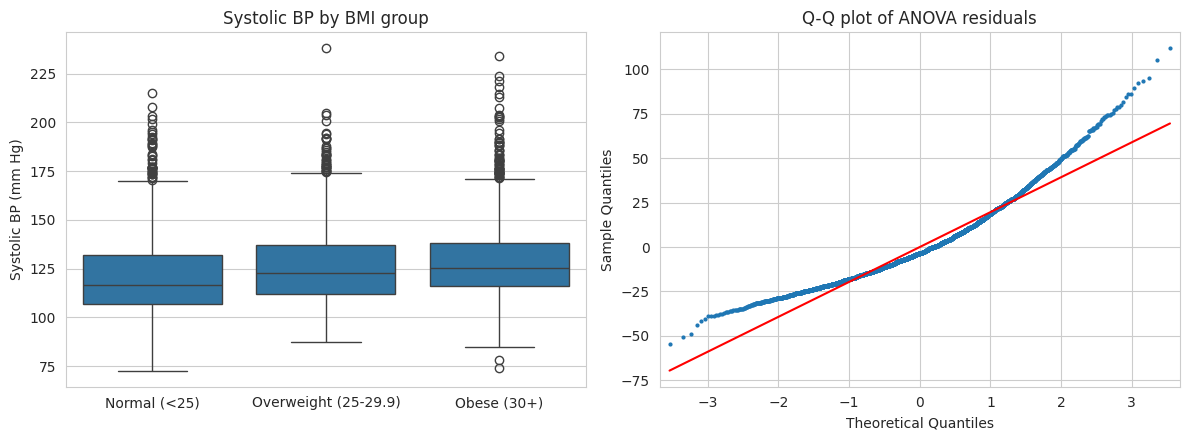

In [10]:
print(cc.groupby("bmi_cat")["sbp"].agg(["count", "mean", "std"]).reindex(BMI_ORDER).round(1))

m1 = smf.ols("sbp ~ C(bmi_cat)", data=cc).fit()
a1 = anova_lm(m1, typ=2)
print("\nOne-way ANOVA"); print(a1.round(4))
eta2 = a1.loc["C(bmi_cat)", "sum_sq"] / a1["sum_sq"].sum()
print(f"Eta squared = {eta2:.4f}")

groups = [g["sbp"].values for _, g in cc.groupby("bmi_cat")]
print("\nLevene p =", pfmt(stats.levene(*groups).pvalue))
print("Kruskal-Wallis p =", pfmt(stats.kruskal(*groups).pvalue))

print("\nTukey post hoc")
tuk = pairwise_tukeyhsd(cc["sbp"], cc["bmi_cat"], alpha=0.05)
print(tuk)

try:
    import pingouin as pg
    print("\nWelch ANOVA (use this if Levene is significant):")
    print(pg.welch_anova(data=cc, dv="sbp", between="bmi_cat").round(4))
except Exception as e:
    print("pingouin step skipped:", e)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=cc, x="bmi_cat", y="sbp", order=BMI_ORDER, ax=ax[0])
ax[0].set_title("Systolic BP by BMI group"); ax[0].set_xlabel(""); ax[0].set_ylabel("Systolic BP (mm Hg)")
sm.qqplot(m1.resid, line="s", ax=ax[1], markersize=2); ax[1].set_title("Q-Q plot of ANOVA residuals")
save("fig3_oneway_anova")

Two-way ANOVA (BMI group x sex)
                         sum_sq      df        F  PR(>F)
C(bmi_cat)         3.786150e+04     2.0  49.2066  0.0000
C(sex)             5.763546e+03     1.0  14.9812  0.0001
C(bmi_cat):C(sex)  5.223282e+03     2.0   6.7884  0.0011
Residual           1.927831e+06  5011.0      NaN     NaN

Cell means
sex                   Female   Male
bmi_cat                            
Normal (<25)           119.4  124.9
Overweight (25-29.9)   125.7  126.5
Obese (30+)            128.2  129.2


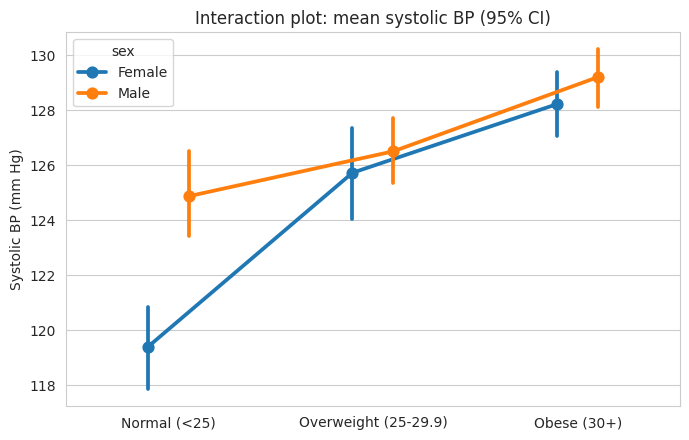

In [11]:
m2 = smf.ols("sbp ~ C(bmi_cat) * C(sex)", data=cc).fit()
a2 = anova_lm(m2, typ=2)
print("Two-way ANOVA (BMI group x sex)")
print(a2.round(4))

print("\nCell means")
print(cc.pivot_table(index="bmi_cat", columns="sex", values="sbp", aggfunc="mean").reindex(BMI_ORDER).round(1))

plt.figure(figsize=(7, 4.5))
sns.pointplot(data=cc, x="bmi_cat", y="sbp", hue="sex", order=BMI_ORDER, dodge=0.2, errorbar=("ci", 95))
plt.title("Interaction plot: mean systolic BP (95% CI)"); plt.xlabel(""); plt.ylabel("Systolic BP (mm Hg)")
save("fig4_twoway_anova")

## 8. ANCOVA (Unit 2)
Question: does systolic BP differ between never, former and current smokers **after adjusting for age**? Age is the covariate. Former smokers tend to be older, so without adjustment their BP looks worse than it is.

Steps: (1) compare unadjusted means and mean age, (2) check the slopes are parallel (the age x smoking interaction should be not significant), (3) fit ANCOVA, (4) get the adjusted means.

Unadjusted means and mean age by smoking group
            n  mean_sbp  mean_age
smoke                            
Never    2972     124.7      46.9
Former   1151     129.7      58.1
Current   894     125.6      47.1

Homogeneity of slopes (look at the interaction row):
                    sum_sq      df          F  PR(>F)
C(smoke)      1.350291e+03     2.0     2.2427  0.1063
age           4.456838e+05     1.0  1480.4992  0.0000
C(smoke):age  1.668502e+03     2.0     2.7713  0.0627
Residual      1.508492e+06  5011.0        NaN     NaN

ANCOVA
                                    sum_sq      df          F  PR(>F)
C(smoke, Treatment("Never"))  1.350291e+03     2.0     2.2412  0.1064
age                           4.456838e+05     1.0  1479.4537  0.0000
Residual                      1.510161e+06  5013.0        NaN     NaN

Adjusted mean systolic BP at age 49.5
          mean  mean_ci_lower  mean_ci_upper
Never    126.1          125.4          126.7
Former   125.2          124.2          126

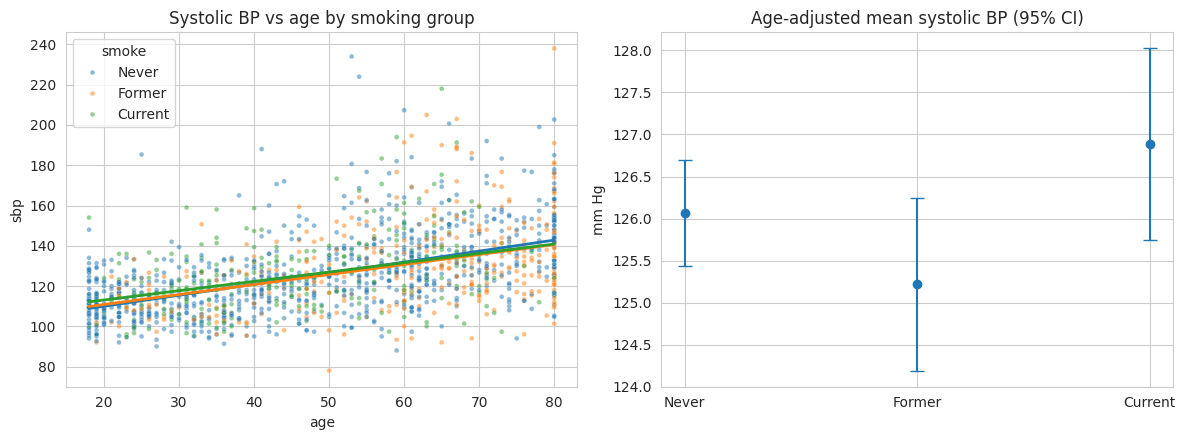

In [12]:
order_s = ["Never", "Former", "Current"]
print("Unadjusted means and mean age by smoking group")
print(cc.groupby("smoke").agg(n=("sbp", "count"), mean_sbp=("sbp", "mean"), mean_age=("age", "mean")).reindex(order_s).round(1))

# 1. homogeneity of regression slopes
m_slope = smf.ols("sbp ~ C(smoke) * age", data=cc).fit()
print("\nHomogeneity of slopes (look at the interaction row):")
print(anova_lm(m_slope, typ=2).round(4))

# 2. ANCOVA
m_anc = smf.ols('sbp ~ C(smoke, Treatment("Never")) + age', data=cc).fit()
print("\nANCOVA")
print(anova_lm(m_anc, typ=2).round(4))

# 3. adjusted means at the mean age
grid = pd.DataFrame({"smoke": order_s, "age": cc["age"].mean()})
adj = m_anc.get_prediction(grid).summary_frame()[["mean", "mean_ci_lower", "mean_ci_upper"]]
adj.index = order_s
print(f"\nAdjusted mean systolic BP at age {cc['age'].mean():.1f}")
print(adj.round(1))

print("\nAdjusted differences (coefficients)")
print(coef_table(m_anc))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
samp = cc.sample(1500, random_state=1)
sns.scatterplot(data=samp, x="age", y="sbp", hue="smoke", hue_order=order_s, s=12, alpha=0.5, ax=ax[0])
for s in order_s:
    g = cc[cc["smoke"] == s]
    b = np.polyfit(g["age"], g["sbp"], 1)
    xs = np.linspace(18, 80, 50)
    ax[0].plot(xs, np.polyval(b, xs), lw=2)
ax[0].set_title("Systolic BP vs age by smoking group")
ax[1].errorbar(order_s, adj["mean"], yerr=[adj["mean"] - adj["mean_ci_lower"], adj["mean_ci_upper"] - adj["mean"]], fmt="o", capsize=5)
ax[1].set_title("Age-adjusted mean systolic BP (95% CI)"); ax[1].set_ylabel("mm Hg")
save("fig5_ancova")

## 9. Repeated measures ANOVA (Unit 2)
Each person has three systolic readings taken a few minutes apart. Does the mean change across the readings? Only people with all three readings are used.

The ANOVA is worked out step by step in the code: the total variation is split into variation between readings, variation between people, and error. The F test compares the "between readings" part with the error. The "between people" part is removed, which is why this test is stronger than a plain one-way ANOVA on the same numbers.

The test assumes sphericity (equal variance of the differences between readings). Mauchly's test checks this, and the Greenhouse-Geisser correction is used if it fails. With thousands of people even a drop of 1 mm Hg is "significant", so also look at the size of the change, not just the p-value.

People with all 3 readings: 4730
           count    mean    std    se
reading                              
Reading 1   4730  125.74  19.68  0.29
Reading 2   4730  125.40  19.63  0.29
Reading 3   4730  124.96  19.37  0.28

Repeated measures ANOVA
                         SS    df
Between readings     1455.8     2
Between people    5300334.6  4729
Error              127008.2  9458
F(2, 9458) = 54.21, p = <0.001
Greenhouse-Geisser epsilon = 0.966, corrected p = <0.001
Partial eta squared = 0.0113

Cross-check with the pingouin package

Mauchly's test of sphericity
SpherResults(spher=False, W=np.float64(0.9646069307817351), chi2=np.float64(170.37152373111522), dof=2, pval=np.float64(1.0099356088652765e-37))

RM ANOVA with Greenhouse-Geisser correction
    Source           SS    DF        MS        F  p_unc  p_GG_corr     ng2     eps sphericity  W_spher  p_spher
0  reading    1455.8461     2  727.9230  54.2067    0.0        0.0  0.0003  0.9658      False   0.9646      0.0
1    Error  1270

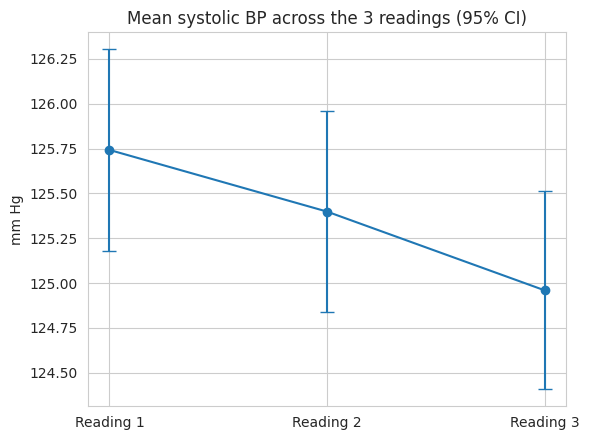

In [13]:
rm = df.dropna(subset=["BPXSY1", "BPXSY2", "BPXSY3"])[["SEQN", "BPXSY1", "BPXSY2", "BPXSY3"]]
long = rm.melt(id_vars="SEQN", value_vars=["BPXSY1", "BPXSY2", "BPXSY3"], var_name="reading", value_name="sbp")
long["reading"] = long["reading"].map({"BPXSY1": "Reading 1", "BPXSY2": "Reading 2", "BPXSY3": "Reading 3"})
print("People with all 3 readings:", rm.shape[0])

summ = long.groupby("reading")["sbp"].agg(["count", "mean", "std"])
summ["se"] = summ["std"] / np.sqrt(summ["count"])
print(summ.round(2))

# Repeated measures ANOVA worked out directly: the variation is split into
# "between readings", "between people" and "error" (what is left over).
wide = rm[["BPXSY1", "BPXSY2", "BPXSY3"]].values
n, k = wide.shape
grand = wide.mean()
ss_read = n * ((wide.mean(axis=0) - grand) ** 2).sum()
ss_person = k * ((wide.mean(axis=1) - grand) ** 2).sum()
ss_total = ((wide - grand) ** 2).sum()
ss_error = ss_total - ss_read - ss_person
df_read, df_error = k - 1, (k - 1) * (n - 1)
F = (ss_read / df_read) / (ss_error / df_error)
p_f = stats.f.sf(F, df_read, df_error)

# Greenhouse-Geisser epsilon from the covariance of the three readings
S = np.cov(wide, rowvar=False)
Sc = S - S.mean(axis=0, keepdims=True) - S.mean(axis=1, keepdims=True) + S.mean()
eps = np.trace(Sc) ** 2 / ((k - 1) * np.sum(Sc ** 2))
p_gg = stats.f.sf(F, df_read * eps, df_error * eps)

print("\nRepeated measures ANOVA")
print(pd.DataFrame({"SS": [ss_read, ss_person, ss_error], "df": [df_read, n - 1, df_error]},
                   index=["Between readings", "Between people", "Error"]).round(1))
print(f"F({df_read}, {df_error}) = {F:.2f}, p = {pfmt(p_f)}")
print(f"Greenhouse-Geisser epsilon = {eps:.3f}, corrected p = {pfmt(p_gg)}")
print(f"Partial eta squared = {ss_read / (ss_read + ss_error):.4f}")

print("\nCross-check with the pingouin package")
try:
    import pingouin as pg
    print("\nMauchly's test of sphericity")
    print(pg.sphericity(long, dv="sbp", within="reading", subject="SEQN"))
    print("\nRM ANOVA with Greenhouse-Geisser correction")
    print(pg.rm_anova(data=long, dv="sbp", within="reading", subject="SEQN", correction=True, detailed=True).round(4))
    print("\nPost hoc: paired t-tests with Bonferroni")
    print(pg.pairwise_tests(data=long, dv="sbp", within="reading", subject="SEQN", padjust="bonf").round(4))
except Exception as e:
    print("pingouin step skipped:", e)

plt.figure(figsize=(6, 4.5))
plt.errorbar(summ.index, summ["mean"], yerr=1.96 * summ["se"], fmt="o-", capsize=5)
plt.title("Mean systolic BP across the 3 readings (95% CI)"); plt.ylabel("mm Hg")
save("fig6_repeated_measures")

## 10. Correlation (Unit 2)
Pearson for the linear relationship, Spearman as a check that does not need normal data.

        Pair    n  Pearson r         95% CI      p  Spearman rho
  bmi vs sbp 5176      0.153 (0.126, 0.180) <0.001         0.187
waist vs sbp 4995      0.224 (0.197, 0.250) <0.001         0.268
  age vs sbp 5247      0.487 (0.466, 0.507) <0.001         0.510
  bmi vs dbp 5159      0.114 (0.087, 0.140) <0.001         0.123
  age vs dbp 5230      0.039 (0.012, 0.066)  0.005         0.041
bmi vs waist 5175      0.905 (0.900, 0.910) <0.001         0.911


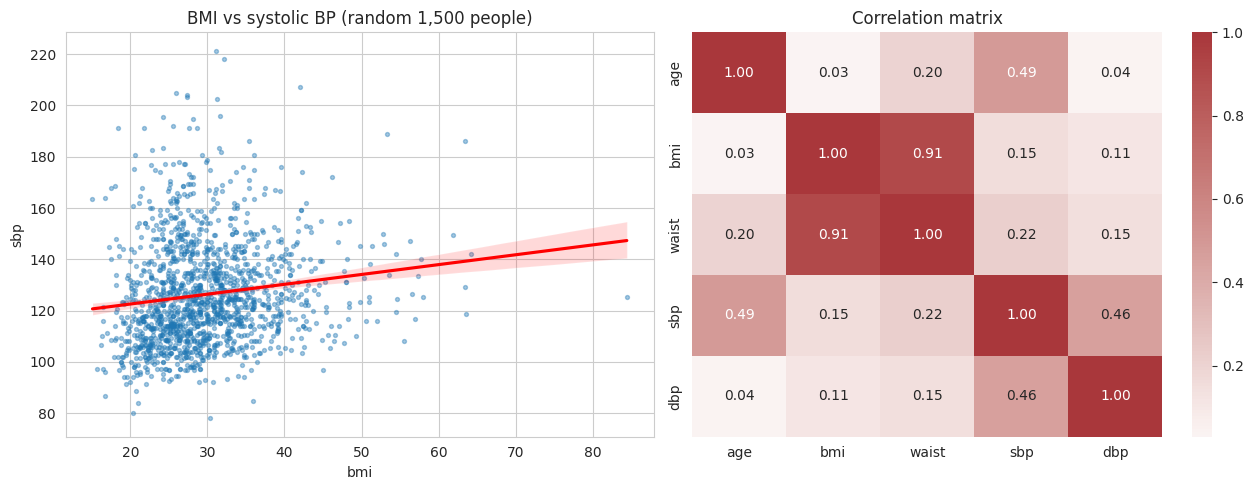

In [14]:
pairs = [("bmi", "sbp"), ("waist", "sbp"), ("age", "sbp"), ("bmi", "dbp"), ("age", "dbp"), ("bmi", "waist")]
rows = []
for x_, y_ in pairs:
    d = df[[x_, y_]].dropna()
    r, p = stats.pearsonr(d[x_], d[y_])
    rho = stats.spearmanr(d[x_], d[y_])[0]
    z, se = np.arctanh(r), 1 / np.sqrt(len(d) - 3)
    rows.append([f"{x_} vs {y_}", len(d), round(r, 3), f"({np.tanh(z-1.96*se):.3f}, {np.tanh(z+1.96*se):.3f})", pfmt(p), round(rho, 3)])
corr = pd.DataFrame(rows, columns=["Pair", "n", "Pearson r", "95% CI", "p", "Spearman rho"])
print(corr.to_string(index=False))
corr.to_csv("results/correlations.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
samp = df.dropna(subset=["bmi", "sbp"]).sample(1500, random_state=1)
sns.regplot(data=samp, x="bmi", y="sbp", scatter_kws={"s": 8, "alpha": 0.4}, line_kws={"color": "red"}, ax=ax[0])
ax[0].set_title("BMI vs systolic BP (random 1,500 people)")
sns.heatmap(df[["age", "bmi", "waist", "sbp", "dbp"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1])
ax[1].set_title("Correlation matrix")
save("fig7_correlation")

## 11. Multiple linear regression and mixed model (Unit 3)
**Linear regression** for mean systolic BP. Coefficients are in mm Hg, for 10 more years of age or 5 more BMI units, with the other variables held fixed. Checks: VIF for multicollinearity (below 5 is fine), Breusch-Pagan for equal variance, residual plots, Cook's distance for influential points.

**Mixed model:** the three readings of the same person are not independent, so a random intercept for each person is added. The ICC says how much of the variation is between people rather than between readings.

Multiple linear regression: n=5017, R2=0.274, adjusted R2=0.272
(coefficients are in mm Hg)

                                         est    low   high       p
sex: Male (vs Female)                  2.387  1.421  3.353  <0.001
smoke: Current (vs Never)              0.456 -0.851  1.763   0.494
smoke: Former (vs Never)              -1.431 -2.659 -0.203   0.022
diabetes: Yes (vs No)                 -1.094 -2.480  0.292   0.122
race: Mexican American (vs NH White)   2.029  0.506  3.551   0.009
race: NH Asian (vs NH White)           2.249  0.711  3.787   0.004
race: NH Black (vs NH White)           6.501  5.233  7.769  <0.001
race: Other Hispanic (vs NH White)     1.880  0.128  3.631   0.035
race: Other/Multiracial (vs NH White)  2.691  0.505  4.877   0.016
age (per 10 years)                     5.353  5.076  5.631  <0.001
BMI (per 5 units)                      1.879  1.546  2.211  <0.001

VIF
sex: Male (vs Female)                    1.06
smoke: Current (vs Never)                1.14
smoke:

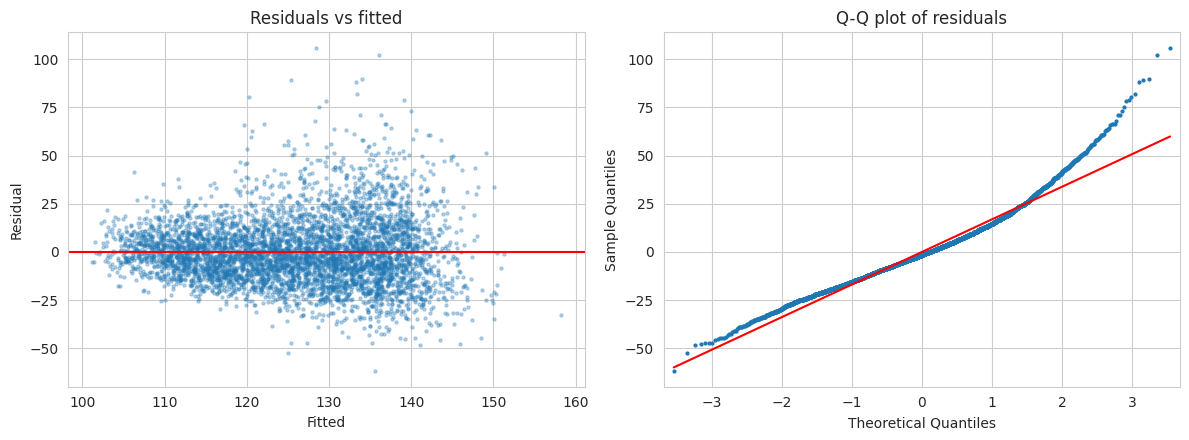

In [15]:
RHS = ('age10 + C(sex, Treatment("Female")) + bmi5 + C(smoke, Treatment("Never")) '
       '+ C(diabetes, Treatment("No")) + C(race, Treatment("NH White"))')

lin = smf.ols("sbp ~ " + RHS, data=cc).fit()
print(f"Multiple linear regression: n={int(lin.nobs)}, R2={lin.rsquared:.3f}, adjusted R2={lin.rsquared_adj:.3f}")
print("(coefficients are in mm Hg)\n")
lin_tab = coef_table(lin)
print(lin_tab)
lin_tab.to_csv("results/linear_regression.csv")

X = pd.DataFrame(lin.model.exog, columns=lin.model.exog_names)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns).drop("Intercept")
vif.index = [nice(i) for i in vif.index]
print("\nVIF"); print(vif.round(2))

bp = het_breuschpagan(lin.resid, lin.model.exog)
print(f"\nBreusch-Pagan p = {pfmt(bp[1])}")
cooks = lin.get_influence().cooks_distance[0]
print(f"Cook's distance: max = {cooks.max():.3f}, people above 4/n = {(cooks > 4 / len(cooks)).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(lin.fittedvalues, lin.resid, s=5, alpha=0.3); ax[0].axhline(0, color="red")
ax[0].set_xlabel("Fitted"); ax[0].set_ylabel("Residual"); ax[0].set_title("Residuals vs fitted")
sm.qqplot(lin.resid, line="s", ax=ax[1], markersize=2); ax[1].set_title("Q-Q plot of residuals")
save("fig8_linear_diagnostics")

In [16]:
long2 = long.merge(cc[["SEQN", "age10", "sex", "bmi5"]], on="SEQN", how="inner")
mm = smf.mixedlm('sbp ~ C(reading) + age10 + C(sex, Treatment("Female")) + bmi5', data=long2, groups=long2["SEQN"]).fit(reml=True)
print(f"Mixed model: {long2['SEQN'].nunique()} people, {len(long2)} readings\n")
print(mm.summary().tables[1])

var_person, var_resid = float(mm.cov_re.iloc[0, 0]), float(mm.scale)
icc = var_person / (var_person + var_resid)
print(f"\nBetween-person variance = {var_person:.1f}, within-person variance = {var_resid:.1f}")
print(f"ICC = {icc:.3f}  (share of variation that is between people)")

Mixed model: 4524 people, 13572 readings

                                       Coef. Std.Err.        z  P>|z|  [0.025  0.975]
Intercept                             89.882    1.217   73.862  0.000  87.497  92.267
C(reading)[T.Reading 2]               -0.346    0.077   -4.486  0.000  -0.497  -0.195
C(reading)[T.Reading 3]               -0.779    0.077  -10.113  0.000  -0.930  -0.628
C(sex, Treatment("Female"))[T.Male]    2.626    0.488    5.384  0.000   1.670   3.582
age10                                  4.874    0.131   37.095  0.000   4.617   5.132
bmi5                                   1.741    0.168   10.340  0.000   1.411   2.071
Group Var                            263.534    1.883                                

Between-person variance = 263.5, within-person variance = 13.4
ICC = 0.951  (share of variation that is between people)


## 12. Logistic regression for hypertension (Unit 3)
Outcome: hypertension (1 = yes). Odds ratios are per 10 years of age and per 5 BMI units; for the categories, they are against the reference group named in brackets.

Checks: VIF, Hosmer-Lemeshow (calibration), ROC and AUC (discrimination), residuals, and an interaction between BMI and sex.

Logistic regression: n=5017, events=2690
Pseudo R2 (McFadden)=0.260, AIC=5154, likelihood ratio test p=<0.001

                                      Crude OR (95% CI) Adjusted OR (95% CI) Adjusted p
age (per 10 years)                     1.95 (1.87-2.03)     2.02 (1.93-2.11)     <0.001
sex: Male (vs Female)                  1.40 (1.25-1.56)     1.60 (1.40-1.84)     <0.001
BMI (per 5 units)                      1.35 (1.30-1.41)     1.46 (1.38-1.53)     <0.001
smoke: Current (vs Never)              1.17 (1.00-1.35)     1.16 (0.97-1.39)      0.112
smoke: Former (vs Never)               1.96 (1.70-2.26)     0.94 (0.78-1.12)      0.464
diabetes: Yes (vs No)                  4.02 (3.35-4.83)     1.28 (1.04-1.58)      0.022
race: Mexican American (vs NH White)   0.71 (0.60-0.85)     1.02 (0.82-1.27)      0.834
race: NH Asian (vs NH White)           0.83 (0.70-0.99)     1.60 (1.29-1.99)     <0.001
race: NH Black (vs NH White)           1.54 (1.32-1.80)     2.15 (1.78-2.60)     <0.001
race: Oth

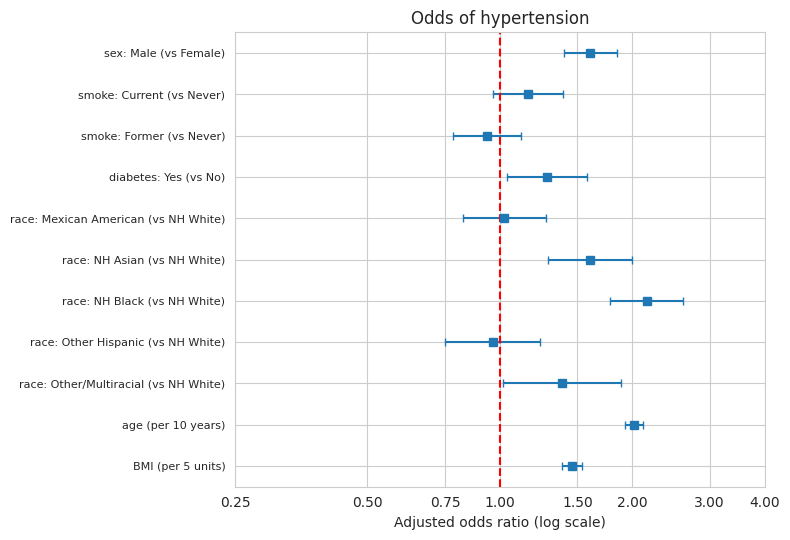

In [17]:
terms = ["age10", 'C(sex, Treatment("Female"))', "bmi5", 'C(smoke, Treatment("Never"))',
         'C(diabetes, Treatment("No"))', 'C(race, Treatment("NH White"))']

crude = pd.concat([coef_table(smf.logit(f"htn ~ {t}", data=cc).fit(disp=0), expo=True) for t in terms])

logit = smf.logit("htn ~ " + RHS, data=cc).fit(disp=0)
adjt = coef_table(logit, expo=True)

def ci_str(r):
    return f"{r['est']:.2f} ({r['low']:.2f}-{r['high']:.2f})"

or_table = pd.DataFrame({
    "Crude OR (95% CI)": crude.apply(ci_str, axis=1),
    "Adjusted OR (95% CI)": adjt.apply(ci_str, axis=1),
    "Adjusted p": adjt["p"],
}).reindex(crude.index)
print(f"Logistic regression: n={int(logit.nobs)}, events={int(cc['htn'].sum())}")
print(f"Pseudo R2 (McFadden)={logit.prsquared:.3f}, AIC={logit.aic:.0f}, likelihood ratio test p={pfmt(logit.llr_pvalue)}\n")
print(or_table.to_string())
or_table.to_csv("results/logistic_odds_ratios.csv")

# forest plot
fp = adjt.copy()
plt.figure(figsize=(8, 5.5))
ys = np.arange(len(fp))[::-1]
plt.errorbar(fp["est"], ys, xerr=[fp["est"] - fp["low"], fp["high"] - fp["est"]], fmt="s", capsize=3)
plt.axvline(1, color="red", ls="--"); plt.xscale("log")
ax_ = plt.gca()
ax_.set_xticks([0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4])
ax_.get_xaxis().set_major_formatter(plt.ScalarFormatter()); ax_.minorticks_off()
plt.yticks(ys, fp.index, fontsize=8); plt.xlabel("Adjusted odds ratio (log scale)")
plt.title("Odds of hypertension")
save("fig9_forest_plot")

Highest VIF: 1.3 (below 5 is fine)
Hosmer-Lemeshow: chi2=30.05, df=8, p=<0.001  (a p above 0.05 means no evidence of poor fit)
AUC = 0.824
At a 0.5 cutoff: sensitivity=0.790, specificity=0.706, accuracy=0.751
Deviance residuals beyond +/-3: 0

Interaction bmi x sex: LR chi2=7.78, p=0.005


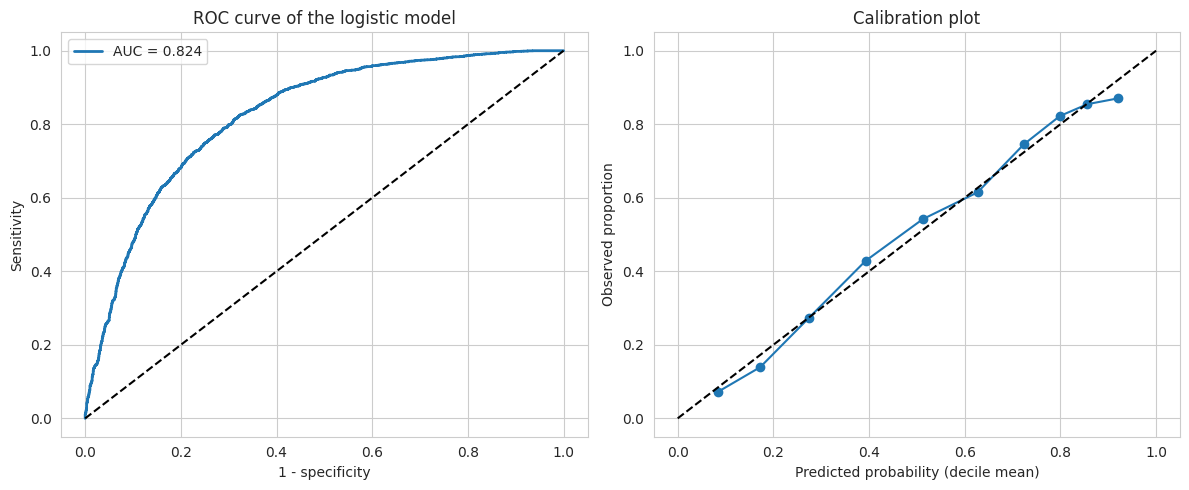

In [18]:
# ---- model checks
Xl = pd.DataFrame(logit.model.exog, columns=logit.model.exog_names)
vif_l = pd.Series([variance_inflation_factor(Xl.values, i) for i in range(Xl.shape[1])], index=Xl.columns).drop("Intercept")
print("Highest VIF:", round(vif_l.max(), 2), "(below 5 is fine)")

def hosmer_lemeshow(y, p, g=10):
    d = pd.DataFrame({"y": y, "p": p})
    d["grp"] = pd.qcut(d["p"], g, duplicates="drop")
    gb = d.groupby("grp", observed=True)
    obs, exp, n = gb["y"].sum(), gb["p"].sum(), gb["y"].count()
    hl = (((obs - exp) ** 2) / (exp * (1 - exp / n))).sum()
    dof = len(n) - 2
    return hl, dof, stats.chi2.sf(hl, dof), obs / n, exp / n

p_hat = logit.predict(cc)
hl, dof, p_hl, obs_rate, exp_rate = hosmer_lemeshow(cc["htn"], p_hat)
print(f"Hosmer-Lemeshow: chi2={hl:.2f}, df={dof}, p={pfmt(p_hl)}  (a p above 0.05 means no evidence of poor fit)")

auc_model = roc_auc_score(cc["htn"], p_hat)
print(f"AUC = {auc_model:.3f}")

pred = (p_hat >= 0.5).astype(int)
tp, fn = ((pred == 1) & (cc["htn"] == 1)).sum(), ((pred == 0) & (cc["htn"] == 1)).sum()
tn, fp_ = ((pred == 0) & (cc["htn"] == 0)).sum(), ((pred == 1) & (cc["htn"] == 0)).sum()
print(f"At a 0.5 cutoff: sensitivity={tp/(tp+fn):.3f}, specificity={tn/(tn+fp_):.3f}, accuracy={(tp+tn)/len(cc):.3f}")

dev = logit.resid_dev
print(f"Deviance residuals beyond +/-3: {(np.abs(dev) > 3).sum()}")

# interaction: does the BMI effect differ by sex?
m_int = smf.logit("htn ~ " + RHS + ' + bmi5:C(sex, Treatment("Female"))', data=cc).fit(disp=0)
lr = 2 * (m_int.llf - logit.llf)
print(f"\nInteraction bmi x sex: LR chi2={lr:.2f}, p={pfmt(stats.chi2.sf(lr, 1))}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(cc["htn"], p_hat)
ax[0].plot(fpr, tpr, lw=2, label=f"AUC = {auc_model:.3f}"); ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set_xlabel("1 - specificity"); ax[0].set_ylabel("Sensitivity"); ax[0].set_title("ROC curve of the logistic model"); ax[0].legend()
ax[1].plot(exp_rate, obs_rate, "o-"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("Predicted probability (decile mean)"); ax[1].set_ylabel("Observed proportion"); ax[1].set_title("Calibration plot")
save("fig10_logistic_checks")

## 13. Screening ability of BMI and waist (Unit 1)
How well can BMI or waist circumference pick out people with hypertension? For each measure: ROC curve, AUC with a bootstrap 95% CI, the best cutoff (Youden index = sensitivity + specificity - 1 is highest), and sensitivity, specificity, PPV and NPV at that cutoff.

Remember: PPV and NPV depend on how common hypertension is in the sample (about 54% here). Sensitivity and specificity do not.

Best cutoff by Youden index
       Measure    n   AUC  AUC_low  AUC_high  Cutoff   TP   FP   FN   TN  Sensitivity  Specificity   PPV   NPV
           BMI 5176 0.620    0.607     0.636    27.9 1748 1055 1050 1323        0.625        0.556 0.624 0.558
   Waist (all) 4995 0.671    0.658     0.685    96.6 1807  969  880 1339        0.672        0.580 0.651 0.603
  Waist (Male) 2455 0.663    0.642     0.683    98.8  939  422  487  607        0.658        0.590 0.690 0.555
Waist (Female) 2540 0.674    0.652     0.695    93.0  910  590  351  689        0.722        0.539 0.607 0.662

Usual cutoffs
                              Rule   TP   FP   FN   TN  Sensitivity  Specificity   PPV   NPV
                         BMI >= 25 2236 1529  562  849        0.799        0.357 0.594 0.602
                         BMI >= 30 1359  773 1439 1605        0.486        0.675 0.637 0.527
Waist >= 102 (men) / >= 88 (women) 1855 1092  832 1216        0.690        0.527 0.629 0.594


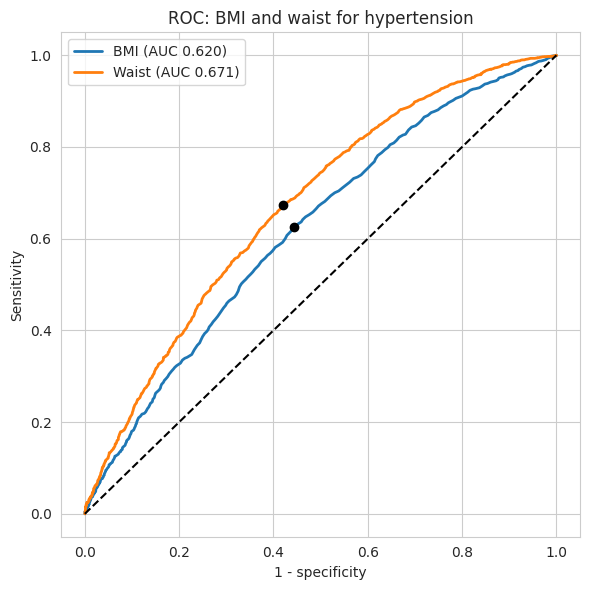

In [19]:
def metrics(pred, y):
    tp, fn = int(((pred == 1) & (y == 1)).sum()), int(((pred == 0) & (y == 1)).sum())
    tn, fp = int(((pred == 0) & (y == 0)).sum()), int(((pred == 1) & (y == 0)).sum())
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, Sensitivity=tp / (tp + fn), Specificity=tn / (tn + fp),
                PPV=tp / (tp + fp) if tp + fp else np.nan, NPV=tn / (tn + fn) if tn + fn else np.nan)

def screen(x, y, name):
    ok = x.notna() & y.notna()
    xv, yv = x[ok].values, y[ok].astype(int).values
    auc = roc_auc_score(yv, xv)
    fpr, tpr, thr = roc_curve(yv, xv)
    k = (tpr - fpr).argmax()
    cut = thr[k]
    rng = np.random.default_rng(1)
    boots = []
    for _ in range(300):
        b = rng.integers(0, len(yv), len(yv))
        if len(np.unique(yv[b])) == 2:
            boots.append(roc_auc_score(yv[b], xv[b]))
    out = dict(Measure=name, n=len(yv), AUC=auc, AUC_low=np.percentile(boots, 2.5), AUC_high=np.percentile(boots, 97.5), Cutoff=cut)
    out.update(metrics((xv >= cut).astype(int), yv))
    return out, (fpr, tpr, k)

res_bmi, roc_bmi = screen(df["bmi"], df["htn"], "BMI")
res_waist, roc_waist = screen(df["waist"], df["htn"], "Waist (all)")
rows = [res_bmi, res_waist]
for s in ["Male", "Female"]:
    sub = df[df["sex"] == s]
    r, _ = screen(sub["waist"], sub["htn"], f"Waist ({s})")
    rows.append(r)

screen_tab = pd.DataFrame(rows)
cols = ["AUC", "AUC_low", "AUC_high", "Cutoff", "Sensitivity", "Specificity", "PPV", "NPV"]
screen_tab[cols] = screen_tab[cols].round(3)
print("Best cutoff by Youden index")
print(screen_tab.to_string(index=False))
screen_tab.to_csv("results/screening_roc.csv", index=False)

# usual cutoffs from guidelines
print("\nUsual cutoffs")
sub = df.dropna(subset=["htn", "bmi"])
std = []
for lab, flag in [("BMI >= 25", sub["bmi"] >= 25), ("BMI >= 30", sub["bmi"] >= 30)]:
    std.append(dict(Rule=lab, **metrics(flag.astype(int).values, sub["htn"].astype(int).values)))
sub = df.dropna(subset=["htn", "waist", "sex"])
flag = ((sub["sex"] == "Male") & (sub["waist"] >= 102)) | ((sub["sex"] == "Female") & (sub["waist"] >= 88))
std.append(dict(Rule="Waist >= 102 (men) / >= 88 (women)", **metrics(flag.astype(int).values, sub["htn"].astype(int).values)))
std_tab = pd.DataFrame(std)
std_tab[["Sensitivity", "Specificity", "PPV", "NPV"]] = std_tab[["Sensitivity", "Specificity", "PPV", "NPV"]].round(3)
print(std_tab.to_string(index=False))
std_tab.to_csv("results/screening_usual_cutoffs.csv", index=False)

plt.figure(figsize=(6, 6))
for lab, (fpr, tpr, k), r in [("BMI", roc_bmi, res_bmi), ("Waist", roc_waist, res_waist)]:
    plt.plot(fpr, tpr, lw=2, label=f"{lab} (AUC {r['AUC']:.3f})")
    plt.plot(fpr[k], tpr[k], "ko")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("1 - specificity"); plt.ylabel("Sensitivity")
plt.title("ROC: BMI and waist for hypertension"); plt.legend()
save("fig11_roc_screening")

## 14. Epidemiology measures (Unit 4)
This is a cross-sectional study, so the measure of disease is **prevalence**, and the comparison is the **prevalence ratio** (PR). Odds ratios are also reported because logistic regression gives them, but when the outcome is common (over 10%) the OR is larger than the PR and should not be read as "times more likely".

The adjusted PR comes from Poisson regression with robust standard errors (modified Poisson), which is the usual way to get a PR for a yes/no outcome.

In [20]:
sub = df.dropna(subset=["htn"])
k, n = int(sub["htn"].sum()), len(sub)
lo, hi = proportion_confint(k, n, method="wilson")
prev = k / n
print(f"Overall hypertension prevalence: {k}/{n} = {prev*100:.1f}% (95% CI {lo*100:.1f}-{hi*100:.1f})\n")

def prev_table(var, order):
    s = df.dropna(subset=["htn", var])
    g = s.groupby(var)["htn"].agg(["sum", "count"]).reindex(order)
    out = []
    for lvl, r in g.iterrows():
        l, h = proportion_confint(r["sum"], r["count"], method="wilson")
        out.append([var, lvl, int(r["count"]), int(r["sum"]), f"{r['sum']/r['count']*100:.1f}", f"{l*100:.1f}-{h*100:.1f}"])
    return out

rows = []
for var, order in [("sex", ["Female", "Male"]), ("age_grp", AGE_ORDER), ("bmi_cat", BMI_ORDER),
                   ("smoke", ["Never", "Former", "Current"]), ("diabetes", ["No", "Yes"])]:
    rows += prev_table(var, order)
prev_tab = pd.DataFrame(rows, columns=["Variable", "Group", "n", "Cases", "Prevalence %", "95% CI"])
print(prev_tab.to_string(index=False))
prev_tab.to_csv("results/prevalence_by_group.csv", index=False)

def two_by_two(s, exposed, label):
    a, b = int((exposed & (s["htn"] == 1)).sum()), int((exposed & (s["htn"] == 0)).sum())
    c, d = int((~exposed & (s["htn"] == 1)).sum()), int((~exposed & (s["htn"] == 0)).sum())
    pr = (a / (a + b)) / (c / (c + d))
    or_ = (a * d) / (b * c)
    se_pr = np.sqrt(1 / a - 1 / (a + b) + 1 / c - 1 / (c + d))
    se_or = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    p = stats.chi2_contingency([[a, b], [c, d]])[1]
    return [label, f"{a}/{a+b}", f"{c}/{c+d}", f"{pr:.2f} ({np.exp(np.log(pr)-1.96*se_pr):.2f}-{np.exp(np.log(pr)+1.96*se_pr):.2f})",
            f"{or_:.2f} ({np.exp(np.log(or_)-1.96*se_or):.2f}-{np.exp(np.log(or_)+1.96*se_or):.2f})", pfmt(p)]

s1 = df.dropna(subset=["htn", "bmi"]);           e1 = s1["bmi"] >= 30
s2 = df.dropna(subset=["htn", "diabetes"]);      e2 = s2["diabetes"] == "Yes"
s3 = df[df["smoke"].isin(["Current", "Never"])].dropna(subset=["htn"]); e3 = s3["smoke"] == "Current"
s4 = df.dropna(subset=["htn", "sex"]);           e4 = s4["sex"] == "Male"
s5 = df.dropna(subset=["htn", "age"]);           e5 = s5["age"] >= 60
crude_tab = pd.DataFrame([
    two_by_two(s1, e1, "Obese (BMI 30+) vs not"),
    two_by_two(s2, e2, "Diabetes vs no diabetes"),
    two_by_two(s3, e3, "Current vs never smoker"),
    two_by_two(s4, e4, "Male vs female"),
    two_by_two(s5, e5, "Age 60+ vs under 60"),
], columns=["Exposure", "Exposed with HTN", "Unexposed with HTN", "Crude PR (95% CI)", "Crude OR (95% CI)", "p (chi-square)"])
print("\nCrude 2x2 comparisons")
print(crude_tab.to_string(index=False))
crude_tab.to_csv("results/crude_pr_or.csv", index=False)

# adjusted PR: modified Poisson
pois = smf.glm("htn ~ " + RHS, data=cc, family=sm.families.Poisson()).fit(cov_type="HC1")
pr_tab = coef_table(pois, expo=True)
cmp_ = pd.DataFrame({"Adjusted PR (95% CI)": pr_tab.apply(ci_str, axis=1), "Adjusted OR (95% CI)": adjt.apply(ci_str, axis=1)})
print("\nAdjusted prevalence ratios (modified Poisson) next to adjusted odds ratios")
print(cmp_.to_string())
cmp_.to_csv("results/adjusted_pr_vs_or.csv")

Overall hypertension prevalence: 2851/5247 = 54.3% (95% CI 53.0-55.7)

Variable                Group    n  Cases Prevalence %    95% CI
     sex               Female 2700   1359         50.3 48.4-52.2
     sex                 Male 2547   1492         58.6 56.7-60.5
 age_grp                18-29  986    133         13.5 11.5-15.8
 age_grp                30-39  759    258         34.0 30.7-37.4
 age_grp                40-49  740    360         48.6 45.1-52.2
 age_grp                50-59  839    560         66.7 63.5-69.9
 age_grp                60-69 1021    785         76.9 74.2-79.4
 age_grp                70-80  902    755         83.7 81.2-86.0
 bmi_cat         Normal (<25) 1411    562         39.8 37.3-42.4
 bmi_cat Overweight (25-29.9) 1633    877         53.7 51.3-56.1
 bmi_cat          Obese (30+) 2132   1359         63.7 61.7-65.8
   smoke                Never 3108   1558         50.1 48.4-51.9
   smoke               Former 1215    800         65.8 63.1-68.5
   smoke           

## 15. Sensitivity analysis
Do the conclusions change if (a) the 140/90 definition is used instead of 130/80, or (b) people with a missing BMI, smoking or diabetes answer are kept by filling the gaps with the median or the most common answer, instead of being dropped? If the odds ratios stay close, the result is stable.

Simple filling understates the real uncertainty, so treat (b) as a rough check only.

In [21]:
def or_est(data, outcome):
    m = smf.logit(f"{outcome} ~ " + RHS, data=data).fit(disp=0)
    t = coef_table(m, expo=True)
    return t.apply(ci_str, axis=1), int(m.nobs)

imp = df.dropna(subset=["sbp"]).copy()
imp["bmi"] = imp["bmi"].fillna(imp["bmi"].median())
imp["bmi5"] = imp["bmi"] / 5
for c in ["smoke", "diabetes", "race", "sex"]:
    imp[c] = imp[c].fillna(imp[c].mode()[0])
imp["htn"] = imp["htn"].astype(int)
imp["htn140"] = imp["htn140"].astype(int)

cc140 = cc.copy(); cc140["htn140"] = cc140["htn140"].astype(int)
a, n_a = or_est(cc, "htn")
b, n_b = or_est(cc140, "htn140")
c_, n_c = or_est(imp, "htn")
sens = pd.DataFrame({f"Main: 130/80, complete cases (n={n_a})": a,
                     f"140/90, complete cases (n={n_b})": b,
                     f"130/80, filled-in data (n={n_c})": c_})
print(sens.to_string())
sens.to_csv("results/sensitivity_analysis.csv")

                                      Main: 130/80, complete cases (n=5017) 140/90, complete cases (n=5017) 130/80, filled-in data (n=5247)
sex: Male (vs Female)                                      1.60 (1.40-1.84)                1.09 (0.94-1.27)                1.59 (1.39-1.83)
smoke: Current (vs Never)                                  1.16 (0.97-1.39)                1.12 (0.92-1.36)                1.13 (0.94-1.35)
smoke: Former (vs Never)                                   0.94 (0.78-1.12)                1.17 (0.98-1.40)                0.91 (0.77-1.09)
diabetes: Yes (vs No)                                      1.28 (1.04-1.58)                1.56 (1.28-1.89)                1.33 (1.08-1.64)
race: Mexican American (vs NH White)                       1.02 (0.82-1.27)                0.89 (0.70-1.12)                1.04 (0.84-1.28)
race: NH Asian (vs NH White)                               1.60 (1.29-1.99)                1.60 (1.27-2.03)                1.62 (1.31-2.00)
race: NH Black (vs N

## 16. Key numbers and download
This prints the numbers you will need for the slides and downloads everything in the `results` folder.

In [22]:
print("KEY NUMBERS")
print(f"Adults: {len(df)} | with BP: {df['sbp'].notna().sum()} | all 3 readings: {len(rm)} | model sample: {len(cc)}")
print(f"Hypertension prevalence: {prev*100:.1f}%")
print(f"Logistic model: AUC={auc_model:.3f}, Hosmer-Lemeshow p={pfmt(p_hl)}")
print(f"BMI screening: AUC={res_bmi['AUC']:.3f}, cutoff={res_bmi['Cutoff']:.1f}, sens={res_bmi['Sensitivity']:.2f}, spec={res_bmi['Specificity']:.2f}")
print(f"Waist screening: AUC={res_waist['AUC']:.3f}, cutoff={res_waist['Cutoff']:.1f}, sens={res_waist['Sensitivity']:.2f}, spec={res_waist['Specificity']:.2f}")
print(f"Mixed model ICC: {icc:.3f}")

shutil.make_archive("results", "zip", "results")
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("results.zip saved (not in Colab, so no automatic download).")

KEY NUMBERS
Adults: 5856 | with BP: 5247 | all 3 readings: 4730 | model sample: 5017
Hypertension prevalence: 54.3%
Logistic model: AUC=0.824, Hosmer-Lemeshow p=<0.001
BMI screening: AUC=0.620, cutoff=27.9, sens=0.62, spec=0.56
Waist screening: AUC=0.671, cutoff=96.6, sens=0.67, spec=0.58
Mixed model ICC: 0.951


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>